In [1]:
import numpy as np

data = np.load("datasets/cifar10.npz")
x_train, y_train = data["x_train"], data["y_train"]
x_test, y_test = data["x_test"], data["y_test"]

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
]

# метки могут быть формы (N, 1) - приводим к (N,)
y_train = y_train.reshape(-1)
y_test = y_test.reshape(-1)

# нормализация в [0, 1]; картинки уже цветные (32, 32, 3), канал добавлять не нужно
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("train:", x_train.shape, y_train.shape)
print("test:", x_test.shape, y_test.shape)

train: (50000, 32, 32, 3) (50000,)
test: (10000, 32, 32, 3) (10000,)


In [2]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,738,890 (6.63 MB)

 Trainable params: 1,738,890 (6.63 MB)

 Non-trainable params: 0 (0.00 B)

In [3]:
history = model.fit(
    x_train, y_train,
    validation_split=0.1,
    epochs=20,
    batch_size=128,
)

test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"test accuracy: {test_acc:.4f}")

Epoch 1/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.1929 - loss: 2.1379 - val_accuracy: 0.2908 - val_loss: 1.9389
Epoch 2/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.2400 - loss: 2.0101 - val_accuracy: 0.3234 - val_loss: 1.9224
Epoch 3/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.2533 - loss: 1.9791 - val_accuracy: 0.3110 - val_loss: 1.9212
Epoch 4/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.2663 - loss: 1.9560 - val_accuracy: 0.3212 - val_loss: 1.9036
Epoch 5/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.2742 - loss: 1.9322 - val_accuracy: 0.3116 - val_loss: 1.9132
Epoch 6/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.2800 - loss: 1.9252 - val_accuracy: 0.3510 - val_loss: 1.8651
Epoch 7/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.2858 - loss: 1.9167 - val_accuracy: 0.3398 - val_loss: 1.8672
Epoch 8/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.2907 - loss: 1.9072 - val_accuracy: 0.

In [4]:
import os

os.makedirs("model", exist_ok=True)
model.save("model/cifar10_cnn.keras")
print("saved to model/cifar10_cnn.keras")

saved to model/cifar10_cnn.keras


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


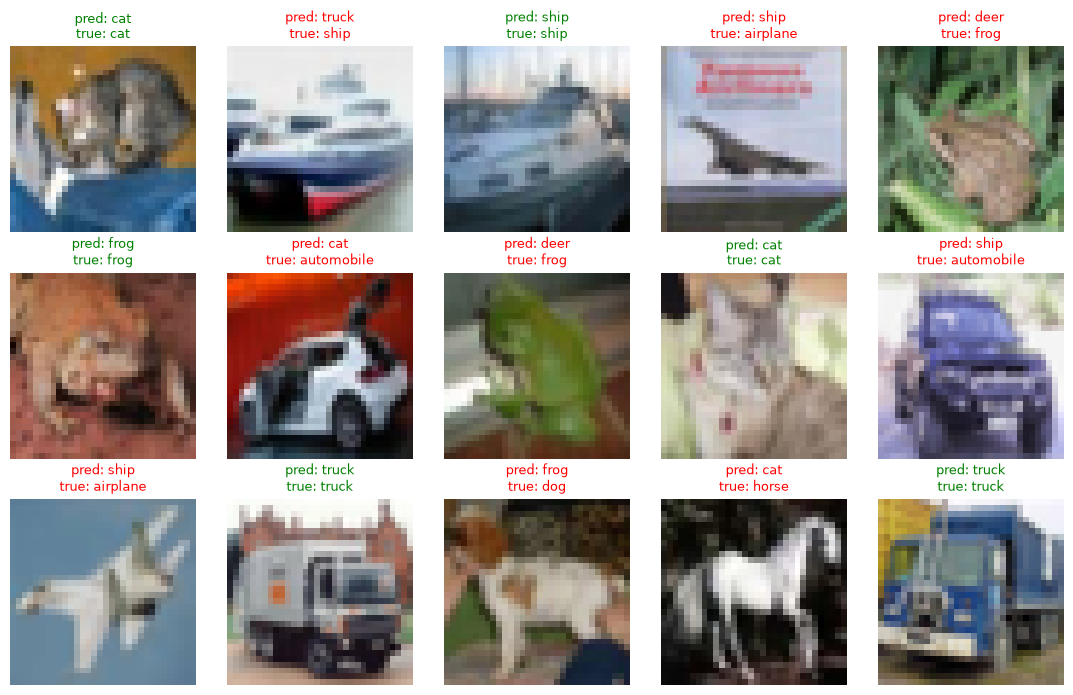

In [5]:
import matplotlib.pyplot as plt

# предсказания на первых 15 тестовых картинках
preds = model.predict(x_test[:15])
pred_labels = preds.argmax(axis=1)

fig, axes = plt.subplots(3, 5, figsize=(11, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i])
    correct = pred_labels[i] == y_test[i]
    ax.set_title(
        f"pred: {class_names[pred_labels[i]]}\ntrue: {class_names[y_test[i]]}",
        color="green" if correct else "red",
        fontsize=9,
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 762us/step


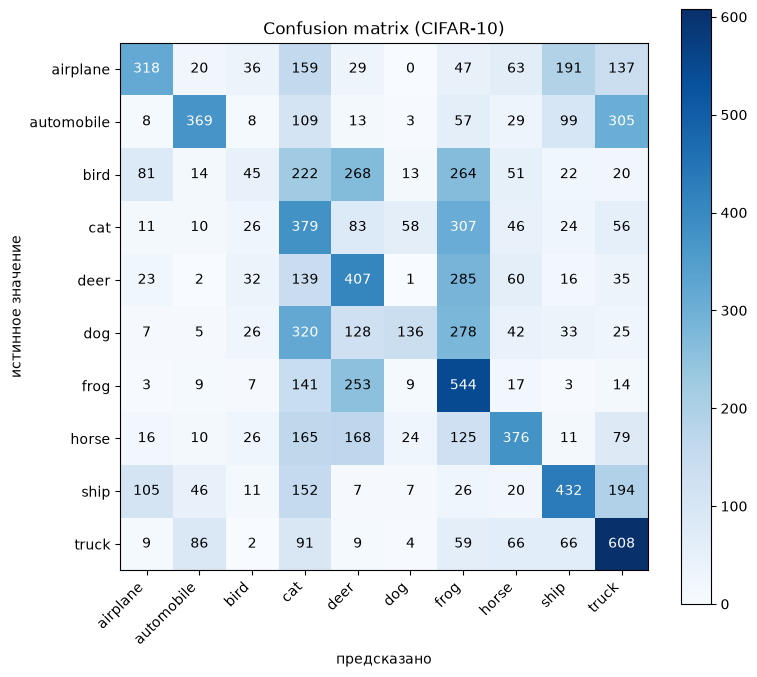

In [6]:
# confusion matrix: какие классы объектов модель чаще всего путает
all_preds = model.predict(x_test).argmax(axis=1)

confusion = np.zeros((10, 10), dtype=int)
for true, pred in zip(y_test, all_preds):
    confusion[true, pred] += 1

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(confusion, cmap="Blues")
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticklabels(class_names)
ax.set_xlabel("предсказано")
ax.set_ylabel("истинное значение")
ax.set_title("Confusion matrix (CIFAR-10)")
for i in range(10):
    for j in range(10):
        ax.text(j, i, confusion[i, j], ha="center", va="center",
                 color="white" if confusion[i, j] > confusion.max() / 2 else "black")
plt.colorbar(im)
plt.tight_layout()
plt.show()